# 01 · PetaBencana: Kualitas Data & Go/No-Go Model B

**Pertanyaan:** apakah laporan banjir PetaBencana.id cukup untuk melatih **Model B (Flood Occurrence Prediction)** per kecamatan Jabodetabek pada H+1?

Syarat *go/no-go* dari PLANNING §7.2:
1. ≥ 3 musim hujan data
2. ≥ 300 pasangan kecamatan-hari positif
3. Model awal mengalahkan aturan ambang hujan di data validasi *(dicek minggu 2–3, bukan di notebook ini)*

Data: arsip `/reports/archive` Desember 2016 – November 2026, diambil 6 Nov 2026. Sumber: **PetaBencana.id**.

```bash
python -m pipeline.ingest.petabencana --start 2016-12 --end 2026-11 --out data/raw/petabencana
```

> Teks laporan berisi nama orang (peserta latihan). Notebook ini sengaja **tidak menampilkan teks laporan**, hanya hitungan.

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
from pipeline.clean import petabencana as pb

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
df = pb.load_archive(ROOT / "data/raw/petabencana")
print(f"{len(df):,} laporan, {df.created_at_wib.min():%Y-%m-%d} s.d. {df.created_at_wib.max():%Y-%m-%d}")
pd.crosstab(df.created_at_wib.dt.year.rename("tahun"), df.disaster_type.rename("jenis"), margins=True, margins_name="total")

119,266 laporan, 2016-12-09 s.d. 2026-11-06


jenis,earthquake,fire,flood,haze,volcano,wind,total
tahun,,,,,,,
2016,0,0,15,0,0,0,15
2017,0,0,4868,0,0,0,4868
2018,0,0,1049,0,0,0,1049
2019,0,0,357,0,0,0,357
2020,724,85,6966,59,92,151,8077
2021,714,128,3275,115,157,563,4952
2022,1487,430,5649,923,497,1917,10903
2023,1825,886,12761,1104,479,2844,19899
2024,5163,2249,21935,2346,2227,4651,38571


## 1. Status `confirmed` tidak berarti kejadian nyata

Semua laporan di arsip berstatus `confirmed`, termasuk laporan **latihan dan uji**: Hari Kesiapsiagaan Bencana (`#HKB`), program duta, kelas kampus/sekolah, pelatihan BPBD, `#112challenge`, dan `partner_code = tescode`. Karena itu penyaringan memakai tiga penanda di `pipeline/clean/petabencana.py`.

In [2]:
print("status:", df.status.value_counts().to_dict())
all_flags = pd.DataFrame({
    "partner tescode": pb.flag_test_partner(df),
    "teks latihan/uji": pb.flag_drill_text(df),
})
pd.DataFrame({"laporan": all_flags.sum(), "porsi": all_flags.mean().map("{:.0%}".format)})

status: {'confirmed': 119266}


,laporan,porsi
partner tescode,1550,1%
teks latihan/uji,90138,76%


## 2. Banjir Jabodetabek setelah dibersihkan

Wilayah: kode BPS kab/kota Jabodetabek, atau kotak koordinat untuk laporan tanpa kode (29% laporan tidak punya `region_code`, 92% tidak punya `district_id`). Ledakan laporan = satu sel ±5 km dalam satu jam berisi ≥10 laporan dengan foto <50%, atau ≥25 laporan. Banjir besar sungguhan (1 Jan 2020, 25 Feb 2020, 20 Feb 2021) paling banyak ±18 per sel-jam dan tidak ikut terbuang.

In [3]:
f = pb.clean_floods(df)
summary = pd.Series({
    "laporan banjir Jabodetabek": len(f),
    "partner tescode": f.is_test_partner.sum(),
    "teks latihan/uji": (f.is_drill_text & ~f.is_test_partner).sum(),
    "ledakan laporan": f.is_burst.sum(),
    "dipertahankan": (~f.is_excluded).sum(),
})
print(summary.to_string(), f"\nporsi dibuang: {f.is_excluded.mean():.0%}")

laporan banjir Jabodetabek    23981
partner tescode                 217
teks latihan/uji              11495
ledakan laporan                1108
dipertahankan                 11161 
porsi dibuang: 53%


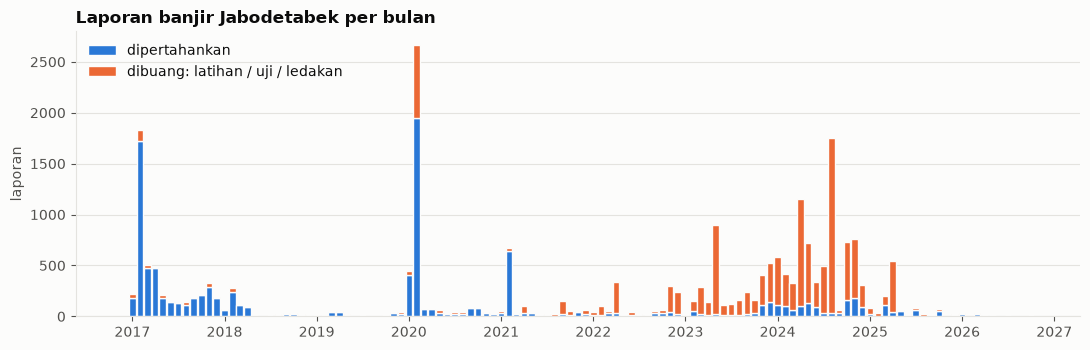

In [4]:
SURFACE, INK, INK2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
KEPT, EXCL = "#2a78d6", "#eb6834"  # slot kategori 1 & 2
plt.rcParams.update({"figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.edgecolor": GRID,
    "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2, "text.color": INK,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})

m = f.assign(bulan=f.created_at_wib.dt.tz_localize(None).dt.to_period("M")) \
     .groupby(["bulan", "is_excluded"]).size().unstack(fill_value=0) \
     .rename(columns={False: "dipertahankan", True: "latihan/uji/ledakan"})
m = m.reindex(pd.period_range(m.index.min(), m.index.max(), freq="M"), fill_value=0)
x = m.index.to_timestamp()
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.bar(x, m["dipertahankan"], width=26, color=KEPT, edgecolor=SURFACE, linewidth=1, label="dipertahankan")
ax.bar(x, m["latihan/uji/ledakan"], width=26, bottom=m["dipertahankan"], color=EXCL, edgecolor=SURFACE, linewidth=1, label="dibuang: latihan / uji / ledakan")
ax.set_title("Laporan banjir Jabodetabek per bulan", loc="left", fontweight="bold")
ax.set_ylabel("laporan"); ax.grid(axis="y", color=GRID, linewidth=0.8); ax.set_axisbelow(True)
ax.legend(frameon=False, loc="upper left")
plt.tight_layout(); plt.show()

## 3. Pasangan kecamatan-hari positif per musim hujan

Poligon kecamatan belum tersedia (minggu 2, PostGIS), jadi sementara dipakai **sel grid 0,05° (±5,5 km, ±30 km²)** sebagai pengganti. Satu kecamatan Jakarta rata-rata ±15 km², jadi di Jakarta angka ini cenderung **lebih kecil** dari hitungan kecamatan sebenarnya.

Musim hujan = November–April, dilabeli tahun mulainya.

In [5]:
k = f[~f.is_excluded].assign(musim=lambda d: pb.rainy_season(d.created_at_wib)).dropna(subset=["musim"])
seasons = k.groupby("musim").apply(lambda g: pd.Series({
    "laporan": len(g), "hari_dengan_laporan": g.date.nunique(),
    "sel_hari_positif": g.groupby(["cell", "date"]).ngroups, "sel_unik": g.cell.nunique(),
    "porsi_berfoto": round(g.has_image.mean(), 2),
}), include_groups=False).astype({"laporan": int, "hari_dengan_laporan": int, "sel_hari_positif": int, "sel_unik": int})
seasons.index = [f"{int(s)}/{str(int(s) + 1)[2:]}" for s in seasons.index]
seasons

,laporan,hari_dengan_laporan,sel_hari_positif,sel_unik,porsi_berfoto
2016/17,2859,106,793,58,0.97
2017/18,978,148,476,46,0.94
2018/19,132,41,83,36,0.71
2019/20,2564,96,495,74,0.80
2020/21,778,98,288,62,0.79
2021/22,156,65,127,47,0.69
2022/23,171,66,138,48,0.67
2023/24,626,121,275,58,0.54
2024/25,452,76,212,55,0.50
2025/26,71,36,54,32,0.73


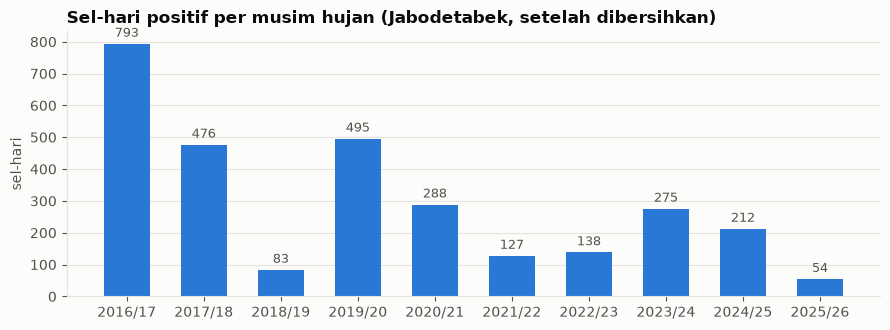

In [6]:
fig, ax = plt.subplots(figsize=(9, 3.4))
bars = ax.bar(seasons.index, seasons.sel_hari_positif, width=0.6, color=KEPT)
ax.bar_label(bars, padding=3, color=INK2, fontsize=9)
ax.set_title("Sel-hari positif per musim hujan (Jabodetabek, setelah dibersihkan)", loc="left", fontweight="bold")
ax.set_ylabel("sel-hari"); ax.grid(axis="y", color=GRID, linewidth=0.8); ax.set_axisbelow(True)
plt.tight_layout(); plt.show()

In [7]:
usable = seasons.loc["2017/18":"2024/25"]  # Historical Forecast tersedia sejak awal 2017; 2025/26 dipisah sebagai uji tambahan
cell_days = k.groupby(["cell", "date"]).size().reset_index()
top = cell_days.cell.value_counts()
print(f"Musim lengkap dengan fitur prakiraan (2017/18–2024/25): {len(usable)} musim, {usable.sel_hari_positif.sum():,} sel-hari positif")
print(f"Musim 2025/26: {seasons.loc['2025/26', 'sel_hari_positif']} sel-hari positif")
print(f"Sel yang pernah positif: {len(top)}; 10 sel teratas menyumbang {top.head(10).sum() / top.sum():.0%} sel-hari")

Musim lengkap dengan fitur prakiraan (2017/18–2024/25): 8 musim, 2,094 sel-hari positif
Musim 2025/26: 54 sel-hari positif
Sel yang pernah positif: 113; 10 sel teratas menyumbang 51% sel-hari


## 4. Keputusan: **GO bersyarat**

| Syarat | Hasil | Status |
|---|---|:-:|
| ≥ 3 musim hujan | 8 musim lengkap (2017/18–2024/25) dengan fitur prakiraan Historical Forecast | ✅ |
| ≥ 300 kecamatan-hari positif | ±2.100 sel-hari (proksi ±5 km) di 8 musim tersebut | ✅ |
| Mengalahkan aturan ambang hujan | Belum diuji | ⏳ minggu 2–3 |

**Yang harus diakui dan masuk rancangan:**
1. **Separuh laporan banjir Jabodetabek adalah latihan atau uji.** Tanpa pembersihan, model akan belajar jadwal latihan (April, Agustus), bukan banjir. Penanda bersifat heuristik; sisa kontaminasi tetap mungkin.
2. **Aktivitas pelapor naik-turun drastis antar-musim** (82 sampai 790 sel-hari), lebih karena pemakaian platform daripada frekuensi banjir. Musim 2025/26 hanya 54 sel-hari. Label sebaiknya dibaca sebagai **"ada laporan banjir warga"**, bukan "terjadi banjir".
3. **Konsentrasi spasial:** separuh sel-hari positif berasal dari 10 sel. Frekuensi historis per sel wajib jadi fitur dan baseline.
4. **Split waktu per musim**, bukan per tahun kalender: latih 2017/18–2022/23, validasi 2023/24, uji 2024/25; 2025/26 sebagai uji tambahan yang tipis.

Kalau syarat ketiga gagal, banjir tetap tampil sebagai informasi tanpa model (laporan warga 🟡 + debit sungai 🔵).